# 01 · Data understanding and EDA
**Problem.** Forecast district-level paddy yield (kg/ha) for a Maha or Yala season *before harvest*, from seasonal weather, irrigation context and recent yield history. Users: Department of Agriculture / Paddy Marketing Board / food-security planners who need early warning of low-yield seasons for stock and import decisions.

**Data**
| Source | Content | Coverage |
|---|---|---|
| Dept. of Census & Statistics (DCS) | District average yield, production, sown and harvested extent | Maha + Yala, 1979 to 2025 |
| Open-Meteo historical API (ERA5) | Daily rain, Tmax, Tmin, FAO-56 ET0 at one paddy-area point per district | 1979 onward |
| NOAA CPC | Oceanic Niño Index (ENSO) | 1950 onward |

One row = one district × one season. Built by `python -m src.features`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import TARGET, WEATHER_FEATURES, HISTORY_FEATURES, FEATURE_DESCRIPTIONS, feature_list

df = pd.read_csv(C.PROCESSED / "model_table.csv")
sns.set_theme(style="whitegrid", context="notebook")
FIG = C.FIGURES
print(df.shape)
df.head()

(2249, 28)


,district,season,season_year,harvested_ha,production_mt,sown_ha,yield_kg_ha,rain_total,rain_establish,rain_late,...,water_balance,rain_anom_pct,t,prev_yield_same,yield_mean3_same,yield_mean5_same,sown_change_pct,prev_yield_any,fertilizer_crisis,oni_mean
0,Ampara,Maha,1978,41779.0,29300.0,44037.0,3124.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
1,Anuradhapura,Maha,1978,72864.0,207000.0,75060.0,3528.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
2,Badulla,Maha,1978,16100.0,27500.0,16337.0,3091.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
3,Batticaloa,Maha,1978,38896.0,27700.0,46002.0,2364.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
4,Colombo,Maha,1978,7059.0,12200.0,7270.0,2038.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667


## 1. Structure, types and coverage

In [2]:
print(f"{df.district.nunique()} districts, seasons {df.season_year.min()}-{df.season_year.max()}")
print(df.groupby("season").size().rename("rows"))
df.info()

25 districts, seasons 1978-2025
season
Maha    1153
Yala    1096
Name: rows, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2249 entries, 0 to 2248
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   district            2249 non-null   object 
 1   season              2249 non-null   object 
 2   season_year         2249 non-null   int64  
 3   harvested_ha        2249 non-null   float64
 4   production_mt       2190 non-null   float64
 5   sown_ha             2249 non-null   float64
 6   yield_kg_ha         2249 non-null   float64
 7   rain_total          2225 non-null   float64
 8   rain_establish      2225 non-null   float64
 9   rain_late           2225 non-null   float64
 10  rain_days           2225 non-null   float64
 11  rain_max5d          2225 non-null   float64
 12  longest_dry_spell   2225 non-null   float64
 13  tmax_mean           2225 non-null   float64
 14  tmin_mean     

In [3]:
df[[TARGET, "sown_ha", "harvested_ha", "production_mt"] + WEATHER_FEATURES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
yield_kg_ha,2249.0,3537.3,841.4,1153.0,2936.0,3499.0,4089.0,6622.0
sown_ha,2249.0,19201.2,19148.0,12.0,6863.0,13092.0,21201.0,127517.0
harvested_ha,2249.0,18296.0,18510.3,11.0,6424.0,12578.0,20171.0,127203.0
production_mt,2190.0,61636.4,73409.5,100.0,18200.0,35700.0,66982.5,530360.0
rain_total,2225.0,931.1,522.8,35.0,526.1,867.3,1245.6,3503.5
rain_establish,2225.0,437.8,260.0,5.9,244.7,396.9,585.4,2059.0
rain_late,2225.0,158.0,135.2,0.0,62.1,119.1,216.5,1024.4
rain_days,2225.0,107.0,37.8,12.0,80.0,103.0,131.0,183.0
rain_max5d,2225.0,131.9,76.0,10.7,83.0,114.6,158.7,657.2
longest_dry_spell,2225.0,16.5,12.8,0.0,8.0,13.0,22.0,95.0


In [4]:
pd.DataFrame({f: FEATURE_DESCRIPTIONS.get(f, "") for f in feature_list(df)}, index=["description"]).T

,description
district,District (categorical)
season,"Maha (Oct-Mar, NE monsoon) or Yala (Apr-Sep, S..."
season_year,Year the season starts - captures the long-run...
fertilizer_crisis,1 for Maha 2021/22 and Yala 2022 (fertilizer i...
prev_yield_same,District yield in the previous season of the s...
prev_yield_any,District yield in the immediately preceding se...
yield_mean3_same,Mean district yield over the last 3 seasons of...
sown_ha,Gross extent sown this season (ha) - known at ...
sown_change_pct,% change in sown extent vs previous same-type ...
rain_total,Total rainfall in the 6-month season window (mm)


## 2. Missing values
Northern districts have gaps during the conflict years (and Kilinochchi / Mullaitivu were only reported separately later). Lag features are missing for each district's first seasons by construction.

,missing_share
yield_mean3_same,0.050
prev_yield_same,0.043
prev_yield_any,0.037
sown_change_pct,0.035
antecedent_rain_6m,0.021
rain_establish,0.011
rain_total,0.011
rain_days,0.011
tmax_mean,0.011
tmin_mean,0.011


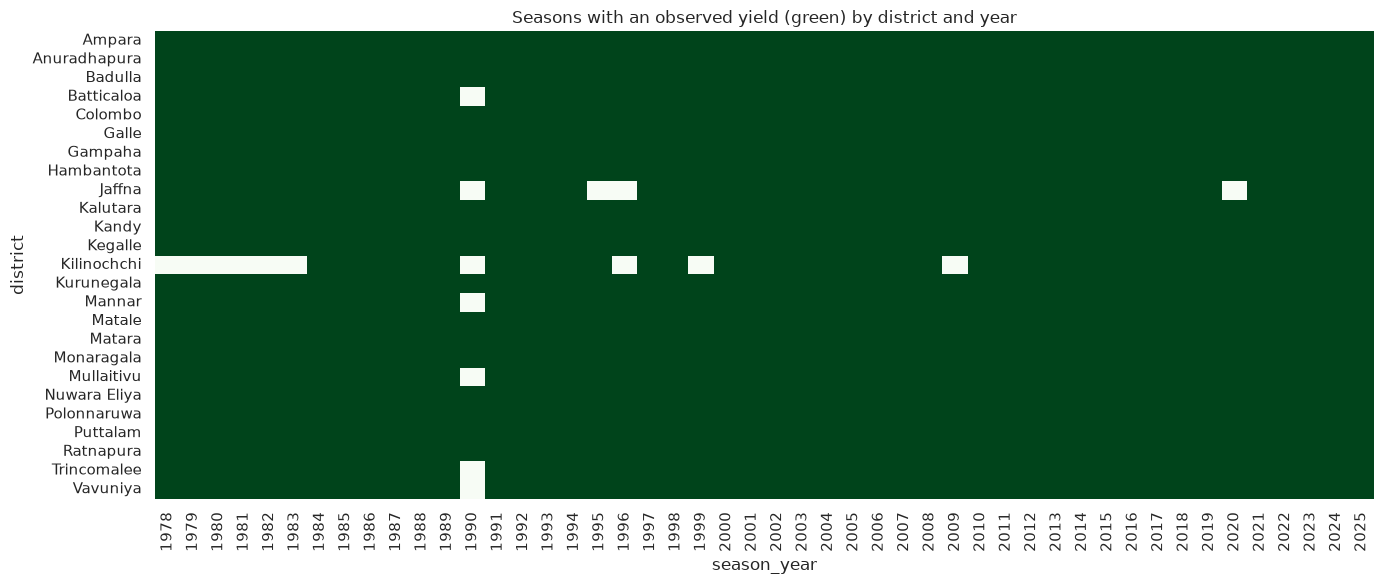

In [5]:
miss = df[feature_list(df) + [TARGET]].isna().mean().sort_values(ascending=False)
display(miss[miss > 0].to_frame("missing_share").round(3))

grid = (df.pivot_table(index="district", columns="season_year", values=TARGET, aggfunc="count")
          .reindex(sorted(C.DISTRICTS)))
plt.figure(figsize=(14, 6))
sns.heatmap(grid.notna() & (grid > 0), cbar=False, cmap="Greens")
plt.title("Seasons with an observed yield (green) by district and year")
plt.tight_layout(); plt.savefig(FIG / "eda_missing_map.png", dpi=150); plt.show()

**Observations**

- About 1.1% of rows have no weather. All of them are Maha 1978, because the ERA5 daily series starts in January 1979.
- `antecedent_rain_6m` is missing in 2.1% of rows. It also needs the six months before Yala 1979.
- Lag features (`prev_yield_*`, `yield_mean3_same`, `sown_change_pct`) are 3.5 to 5% missing: each district's first seasons, and the season after any gap.
- Gaps cluster in the north and east. 1990 is missing for Jaffna, Mullaitivu, Mannar, Vavuniya, Batticaloa and Trincomalee.
- Kilinochchi starts in 1984 and also misses 1990, 1996, 1999 and 2009.
- Jaffna has the fewest rows (49), and only 5 of them are Yala.
- Maha 2020 has no rows for any district.

## 3. Target: yield distribution and trend

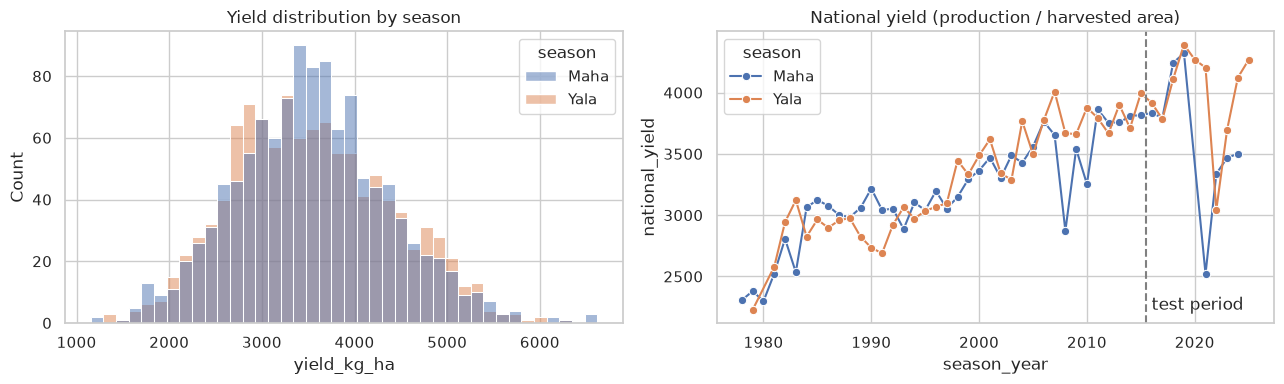

skewness: 0.25


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df, x=TARGET, hue="season", bins=40, ax=ax[0])
ax[0].set_title("Yield distribution by season")
nat = (df.dropna(subset=["production_mt"]).groupby(["season_year", "season"])
         .apply(lambda g: 1000 * g.production_mt.sum() / g.harvested_ha.sum()).rename("national_yield").reset_index())
sns.lineplot(nat, x="season_year", y="national_yield", hue="season", marker="o", ax=ax[1])
ax[1].axvline(C.TRAIN_END + 0.5, ls="--", c="grey"); ax[1].text(C.TRAIN_END + 1, nat.national_yield.min(), "test period")
ax[1].set_title("National yield (production / harvested area)")
plt.tight_layout(); plt.savefig(FIG / "eda_target.png", dpi=150); plt.show()
print("skewness:", df[TARGET].skew().round(2))

**Observations**

- Maha and Yala look alike: medians of 3,518 and 3,474 kg/ha, standard deviations of about 830 and 855.
- Skewness is 0.25, so the target needs no log transform.
- National yield rose from about 2,300 kg/ha in the late 1970s to about 4,300 in 2019. `season_year` and the lag features will carry much of the signal.
- The biggest drops are Maha 2008 (2,872, down from 3,654) and the fertilizer ban (Maha 2021/22 at 2,521, Yala 2022 at 3,043).
- Yields recovered in 2023 and 2024 but are still below the 2019 peak.
- The test period (2016 onward) contains the crisis. That makes it harder than a random split, and closer to real use.
- The national line has no point for Maha 2020 (no rows) or Maha 2025 (production not yet reported).

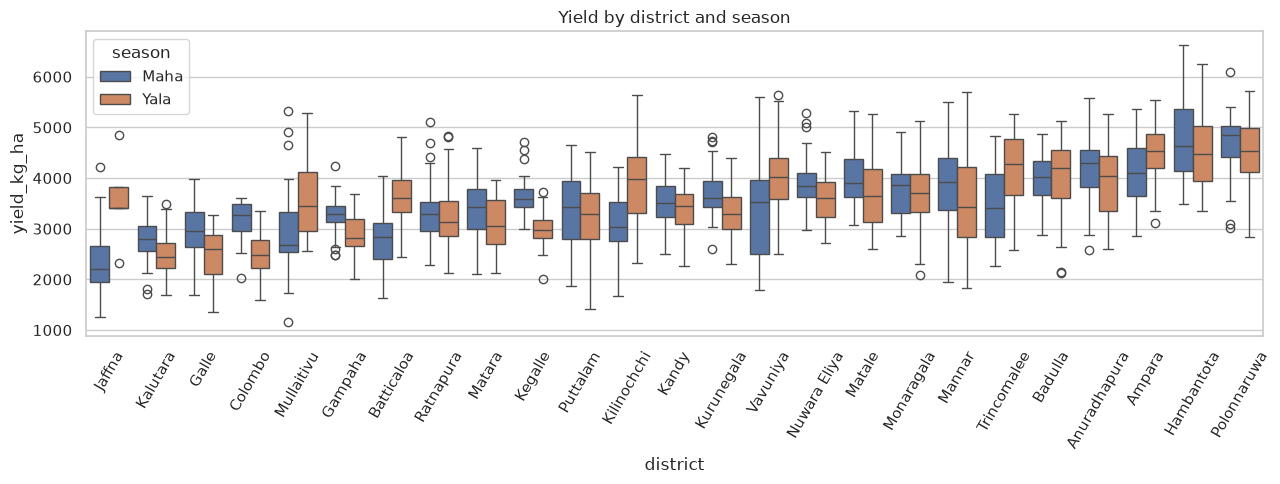

In [7]:
order = df.groupby("district")[TARGET].median().sort_values().index
plt.figure(figsize=(13, 5))
sns.boxplot(df, x="district", y=TARGET, hue="season", order=order)
plt.xticks(rotation=60); plt.title("Yield by district and season")
plt.tight_layout(); plt.savefig(FIG / "eda_district_box.png", dpi=150); plt.show()

**Observations**

- District matters more than season. The highest medians are in the irrigated dry zone: Polonnaruwa (4,731 kg/ha), Hambantota (4,588), Ampara (4,292) and Anuradhapura (4,158).
- The lowest are Jaffna (2,246) and the wet-zone south-west: Kalutara (2,646), Galle (2,678) and Colombo (2,922).
- The season effect flips by region. Yala is higher in the north and east (Jaffna by about 1,200 kg/ha, Kilinochchi 950, Trincomalee 860). Maha is higher in the wet zone (Colombo by about 800, Kegalle 600).
- The two cancel out nationally, so the model has to learn a district by season interaction.
- Variability differs too. The coefficient of variation is about 0.13 in Kandy, Nuwara Eliya, Gampaha and Polonnaruwa, 0.24 to 0.26 in Kilinochchi, Mannar, Vavuniya and Mullaitivu, and 0.30 in Jaffna.
- Expect larger forecast errors in the northern districts.

## 4. Outliers
IQR rule within each district and season. These are real shocks (droughts, floods, policy), not data errors, so they are kept. Removing them would teach the model that bad seasons never happen.

In [8]:
def iqr_flags(g):
    q1, q3 = g[TARGET].quantile([.25, .75]); iqr = q3 - q1
    return (g[TARGET] < q1 - 1.5 * iqr) | (g[TARGET] > q3 + 1.5 * iqr)
df["iqr_outlier"] = df.groupby(["district", "season"], group_keys=False).apply(iqr_flags)
print(f"{df.iqr_outlier.sum()} outlier rows ({100 * df.iqr_outlier.mean():.1f}%)")
df[df.iqr_outlier].sort_values(TARGET)[["district", "season", "season_year", TARGET, "rain_anom_pct", "fertilizer_crisis"]].head(15)

41 outlier rows (1.8%)


,district,season,season_year,yield_kg_ha,rain_anom_pct,fertilizer_crisis
256,Mullaitivu,Maha,1983,1153.0,73.939177,0
9,Kalutara,Maha,1978,1707.0,NaN,0
56,Kalutara,Maha,1979,1803.0,7.818491,0
35,Kegalle,Yala,1979,2012.0,-19.266086,0
4,Colombo,Maha,1978,2038.0,NaN,0
87,Monaragala,Yala,1980,2084.0,3.028995,0
73,Badulla,Yala,1980,2134.0,1.552822,0
121,Badulla,Yala,1981,2146.0,5.797399,0
32,Jaffna,Yala,1979,2318.0,-20.614165,0
53,Gampaha,Maha,1979,2473.0,18.509834,0


**Observations**

- 41 rows (1.8%) are flagged: 17 low and 24 high.
- Most reflect the long-run trend. Low flags cluster in 1978 to 1983 and high flags from 2012, especially 2017 to 2019, because a fixed per-district IQR ignores the rise in yield.
- The fertilizer crisis barely shows up. Only Polonnaruwa Maha 2021 is flagged (3,103 kg/ha against a district median of 4,848).
- Comparing each season with the previous-5 mean (section 5) picks out real shocks better.
- The lowest value is Mullaitivu Maha 1983, at 1,153 kg/ha.
- All flagged rows are kept.

## 5. Weather vs yield

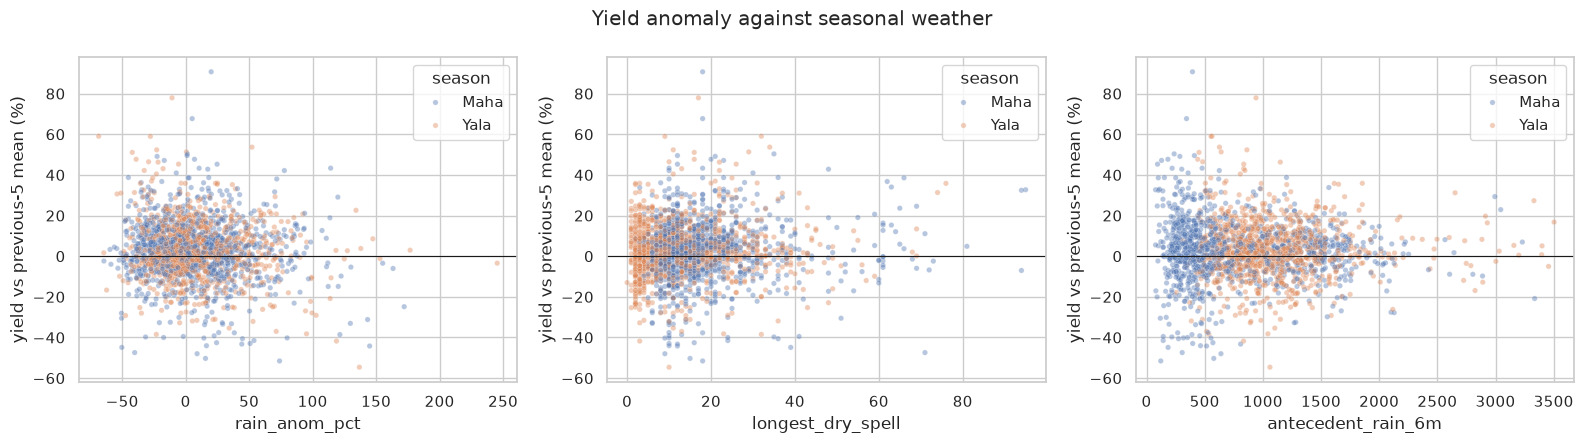

In [9]:
df["yield_anom_pct"] = 100 * (df[TARGET] / df["yield_mean5_same"] - 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, f in zip(ax, ["rain_anom_pct", "longest_dry_spell", "antecedent_rain_6m"]):
    sns.scatterplot(df, x=f, y="yield_anom_pct", hue="season", alpha=.4, s=15, ax=a)
    a.axhline(0, c="k", lw=.8); a.set_ylabel("yield vs previous-5 mean (%)")
plt.suptitle("Yield anomaly against seasonal weather"); plt.tight_layout()
plt.savefig(FIG / "eda_weather_scatter.png", dpi=150); plt.show()

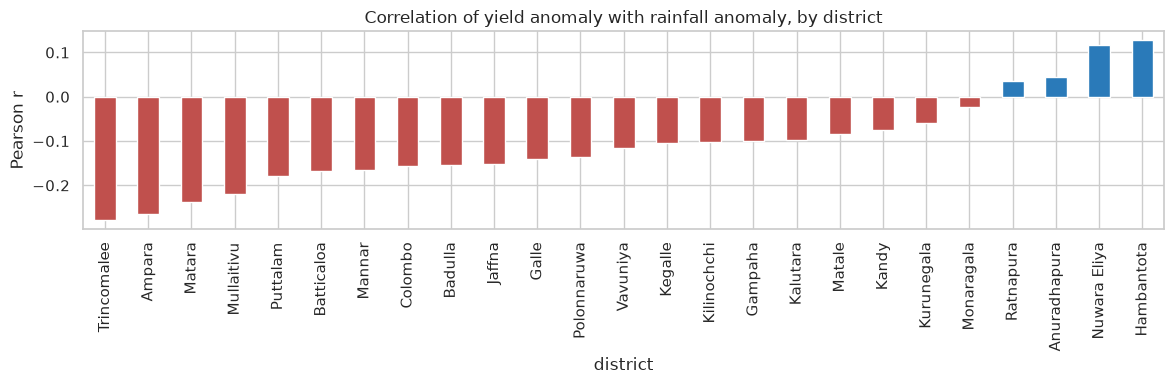

In [10]:
sens = (df.dropna(subset=["yield_anom_pct", "rain_anom_pct"]).groupby("district")
          .apply(lambda g: g["yield_anom_pct"].corr(g["rain_anom_pct"])).sort_values())
plt.figure(figsize=(12, 4)); sens.plot.bar(color=np.where(sens > 0, "#2a7ab9", "#c0504d"))
plt.title("Correlation of yield anomaly with rainfall anomaly, by district"); plt.ylabel("Pearson r")
plt.tight_layout(); plt.savefig(FIG / "eda_rain_sensitivity.png", dpi=150); plt.show()

**Observations**

- Weather has a weak link to the yield anomaly: r = -0.11 for `rain_anom_pct`, 0.05 for `longest_dry_spell` and -0.03 for `antecedent_rain_6m`.
- Too much rain hurts more than too little. Seasons more than 60% above normal average -0.5% against the previous-5 mean; near-normal seasons average about +3%.
- Very dry seasons (more than 40% below normal) average +2.0%, so there is no drought penalty on average.
- A likely reason: most paddy is irrigated, which buffers drought but not flooding.
- By district the correlation is negative almost everywhere, strongest in Trincomalee (-0.28), Ampara (-0.26) and Matara (-0.24).
- Only Ratnapura, Anuradhapura, Nuwara Eliya and Hambantota are slightly positive (0.04 to 0.13).
- Weather alone will not drive the forecast. It should matter most in extreme seasons.

## 6. Correlations and multicollinearity

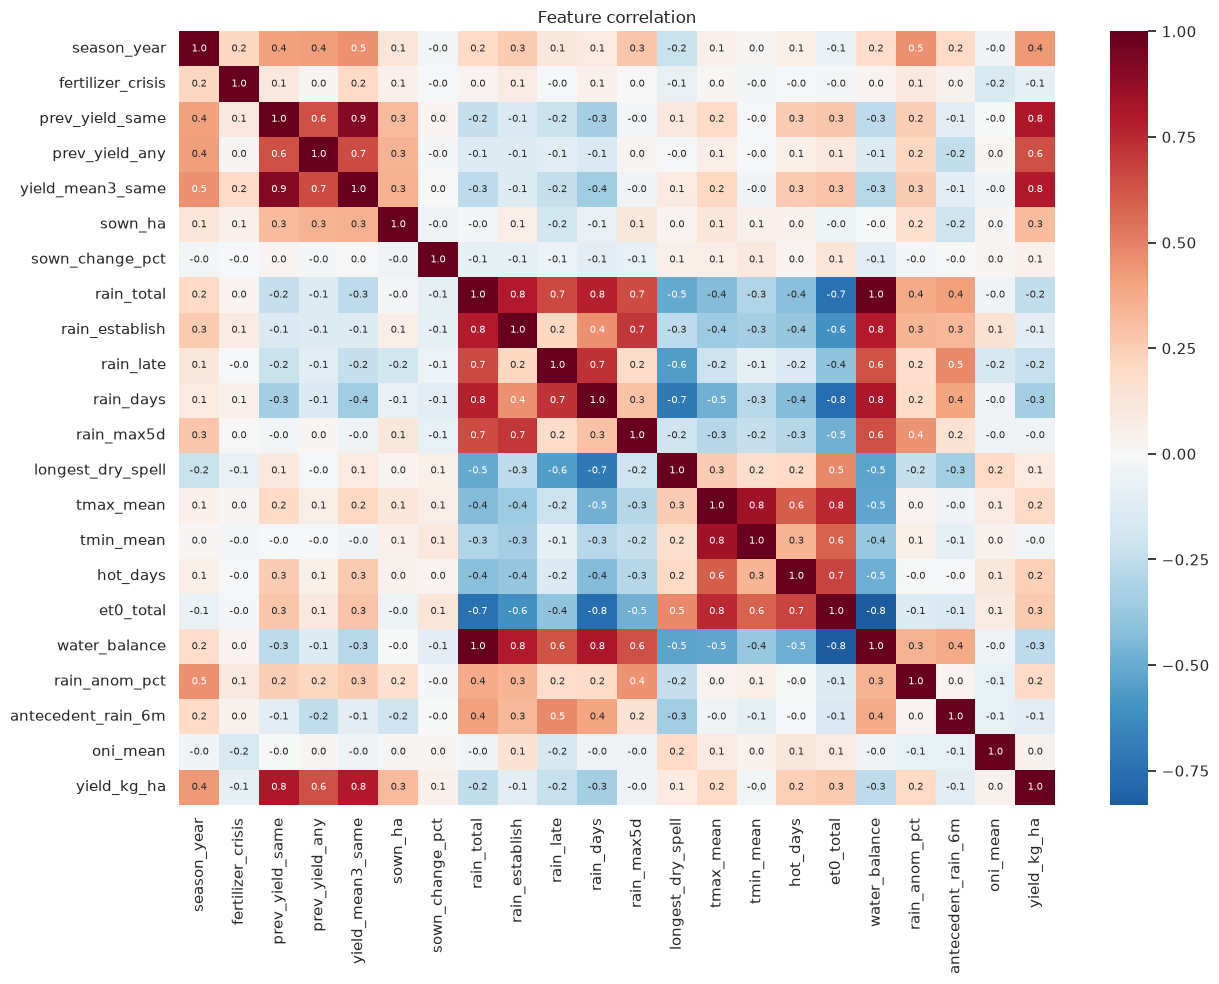

,,|r|
rain_total,water_balance,0.989092
prev_yield_same,yield_mean3_same,0.916638
tmax_mean,tmin_mean,0.847200
et0_total,water_balance,0.830705
rain_days,water_balance,0.807349
prev_yield_same,yield_kg_ha,0.801392


In [11]:
num = [f for f in feature_list(df) if f not in ("district", "season")] + [TARGET]
corr = df[num].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Feature correlation"); plt.tight_layout(); plt.savefig(FIG / "eda_corr.png", dpi=150); plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False))
pairs[pairs > .8].to_frame("|r|")

**Observations**

- The strongest correlates of yield are all history: `prev_yield_same` (0.80), `yield_mean3_same` (0.80), `prev_yield_any` (0.65) and `season_year` (0.43).
- Rain features correlate negatively with yield level (`rain_days` -0.34, `rain_total` -0.25) but hardly with the anomaly (-0.07 and -0.06).
- That level effect is between districts: wet-zone districts get more rain and also have lower yields. It does not mean more rain lowers yield within a district.
- Near-duplicate pairs: `rain_total` and `water_balance` (0.99), `prev_yield_same` and `yield_mean3_same` (0.92), `tmax_mean` and `tmin_mean` (0.85), `et0_total` and `water_balance` (0.83), `rain_days` and `water_balance` (0.81).
- Trees cope with this; linear models need regularisation. Importance scores will be split between correlated features.
- `fertilizer_crisis` has the strongest correlation with the anomaly (-0.34), though it covers only two seasons.